# Polynomial Features

## Learning objectives
- Generate powers and interactions using `PolynomialFeatures`.
- Compare polynomial degrees.
- Use polynomial features in a regression pipeline.

In [1]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
X = pd.DataFrame({"HoursStudied": [1, 2, 3, 4, 5], "PracticeTests": [0, 1, 1, 2, 3]})
X

,HoursStudied,PracticeTests
0,1,0
1,2,1
2,3,1
3,4,2
4,5,3


In [2]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)
pd.DataFrame(X_poly, columns=poly.get_feature_names_out(X.columns))

,HoursStudied,PracticeTests,HoursStudied^2,HoursStudied PracticeTests,PracticeTests^2
0,1.0,0.0,1.0,0.0,0.0
1,2.0,1.0,4.0,2.0,1.0
2,3.0,1.0,9.0,3.0,1.0
3,4.0,2.0,16.0,8.0,4.0
4,5.0,3.0,25.0,15.0,9.0


## 1. Compare degrees
Higher degrees can create many more features and increase overfitting risk.

In [3]:
for degree in [1, 2, 3, 4]:
    transformer = PolynomialFeatures(degree=degree, include_bias=False)
    print(degree, transformer.fit_transform(X).shape[1], transformer.get_feature_names_out(X.columns).tolist())

1 2 ['HoursStudied', 'PracticeTests']
2 5 ['HoursStudied', 'PracticeTests', 'HoursStudied^2', 'HoursStudied PracticeTests', 'PracticeTests^2']
3 9 ['HoursStudied', 'PracticeTests', 'HoursStudied^2', 'HoursStudied PracticeTests', 'PracticeTests^2', 'HoursStudied^3', 'HoursStudied^2 PracticeTests', 'HoursStudied PracticeTests^2', 'PracticeTests^3']
4 14 ['HoursStudied', 'PracticeTests', 'HoursStudied^2', 'HoursStudied PracticeTests', 'PracticeTests^2', 'HoursStudied^3', 'HoursStudied^2 PracticeTests', 'HoursStudied PracticeTests^2', 'PracticeTests^3', 'HoursStudied^4', 'HoursStudied^3 PracticeTests', 'HoursStudied^2 PracticeTests^2', 'HoursStudied PracticeTests^3', 'PracticeTests^4']


## 2. Compare linear and polynomial regression

Degree 1: MAE=2.234, R2=0.515
Degree 2: MAE=0.763, R2=0.939


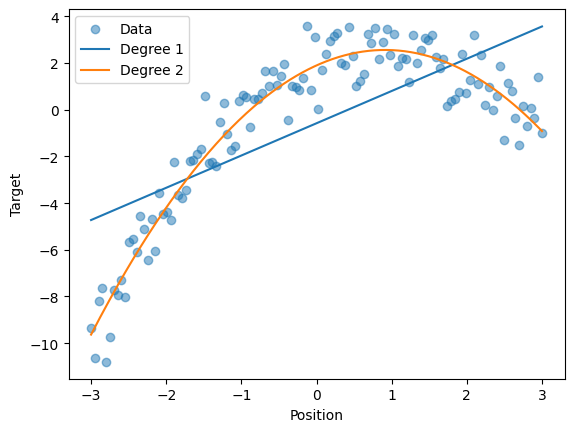

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.default_rng(42)
X_reg = pd.DataFrame({"Position": np.linspace(-3, 3, 120)})
y = 2 + 1.5*X_reg["Position"] - 0.8*X_reg["Position"]**2 + rng.normal(0, 1.2, 120)
X_train, X_test, y_train, y_test = train_test_split(X_reg, y, test_size=0.2, random_state=42)
models = {}
for degree in [1, 2]:
    model = Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)), ("regressor", LinearRegression())])
    model.fit(X_train, y_train)
    models[degree] = model
    pred = model.predict(X_test)
    print(f"Degree {degree}: MAE={mean_absolute_error(y_test, pred):.3f}, R2={r2_score(y_test, pred):.3f}")
grid = pd.DataFrame({"Position": np.linspace(-3, 3, 300)})
plt.scatter(X_reg["Position"], y, alpha=.5, label="Data")
for degree, model in models.items(): plt.plot(grid["Position"], model.predict(grid), label=f"Degree {degree}")
plt.xlabel("Position"); plt.ylabel("Target"); plt.legend(); plt.show()

## Key takeaways
- Polynomial features allow linear estimators to fit nonlinear patterns.
- `include_bias=False` avoids a redundant constant feature when the estimator fits an intercept.
- Choose degree using validation or cross-validation.